In [22]:
import torch 


In [23]:
print(torch.__version__)

2.11.0+cu128


In [24]:
print(torch.cuda.is_available())

True


In [25]:
#le nombre de colonnes de la première matrice (A) soit égal au nombre de lignes de la seconde matrice (B). 

In [26]:
X = torch.linspace(-2, 2, 120).unsqueeze(1)

In [27]:
print(X.shape)

torch.Size([120, 1])


In [28]:
noise = torch.randn_like(X) * 0.6

In [29]:
y = 3 * X + 2 + noise
print(y.shape)

torch.Size([120, 1])


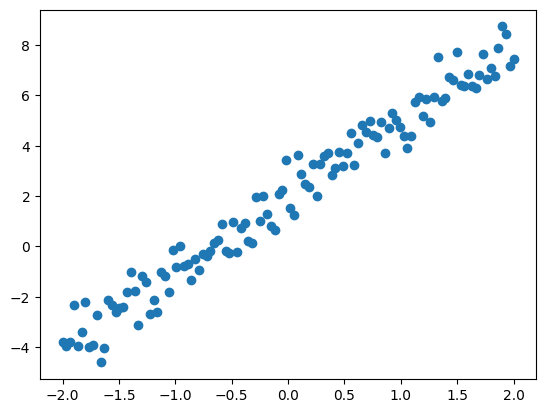

In [30]:
import matplotlib.pyplot as plt
plt.scatter(X, y)

In [31]:
import torch.nn as nn


In [32]:
model = nn.Linear(1, 1)

In [33]:
loss_function = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
epochs = 500
losses = []
for epoch in range(epochs):
    y_pred = model(X)
    loss = loss_function(y_pred, y)
    optimizer.zero_grad()
    loss.backward()
    losses.append(loss.item())
    optimizer.step()

    if epoch % 100 == 0:
        print(f'Epoch {epoch}, Loss: {loss.item()}')

Epoch 0, Loss: 13.932512283325195
Epoch 100, Loss: 0.4924083352088928
Epoch 200, Loss: 0.41672807931900024
Epoch 300, Loss: 0.4160551428794861
Epoch 400, Loss: 0.41604602336883545


In [34]:
with torch.inference_mode():
    y_pred = model(X)

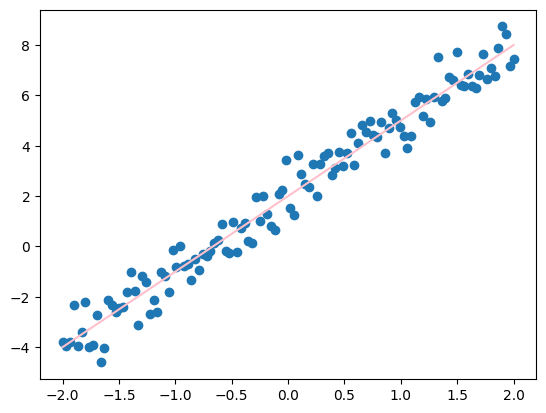

In [35]:
plt.scatter(X, y)
plt.plot(X, y_pred, color='pink')
plt.show()

In [36]:
from torcheval.metrics import R2Score
metric = R2Score()
metric.update(y_pred, y)
r2=metric.compute()
print(f"R2 Score = {r2:.3f}")

R2 Score = 0.967


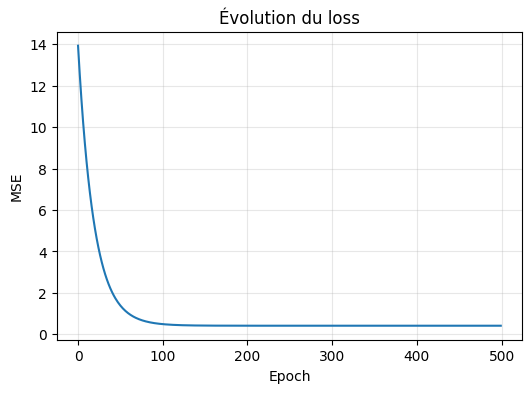

In [37]:
plt.figure(figsize=(6,4))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Évolution du loss")
plt.grid(True, alpha=0.3)
plt.show()